# Gender Name Classification with Naïve Bayes

In this lab, we will build a **gender name classifier** using the **Naïve Bayes** method (following the NLTK book, Chapter 6, https://www.nltk.org/book/ch06.html). The goal is not just to classify names, but to understand the full supervised learning workflow.

Through this activity, you will learn how to:

- Split data into **training**, **development-test**, and **test** sets  
- Build and train a **Naïve Bayes classifier**  
- Evaluate model performance using **accuracy** and a **confusion matrix**  
- Use a **development-test set** to analyze error patterns and guide model improvements  
- Make **incremental feature engineering improvements** and compare models  

Rather than treating machine learning as a black box, this exercise will help you see how small feature changes can meaningfully affect classification performance.

---

## Your Task

Your main task is to **complete the feature extraction function** that defines which properties of a name the classifier will use (e.g., last letter, suffixes, length, etc.).

You will:

- Implement additional features inside the provided function.  
- Train the classifier using your features.  
- Evaluate accuracy on the development-test set.  
- Compare different feature combinations.  
- Reflect on which features improve performance and why.  

The key learning objective is to understand how **feature design directly impacts model performance**.

---

## Important Instructions

Throughout the notebook, look for sections labeled:


# YOUR TURN

There are **five places** marked "YOUR TURN". They indicate places where you are expected to write code, make decisions, or run experiments. Do not skip these sections — they are where the learning happens.

# 0_data preparation

In [ ]:
import nltk
nltk.download('names')

[nltk_data] Downloading package names to /root/nltk_data...
[nltk_data]   Package names is already up-to-date!


True

In [ ]:
from nltk.corpus import names

In [ ]:
names.words("female.txt")[:5]

['Abagael', 'Abagail', 'Abbe', 'Abbey', 'Abbi']

In [ ]:
names.words("male.txt")[:5]

['Aamir', 'Aaron', 'Abbey', 'Abbie', 'Abbot']

In [ ]:
labeled_names = [(name, 'male') for name in names.words('male.txt')] + [(name, 'female') for name in names.words('female.txt')]

In [ ]:
labeled_names[:5]

[('Aamir', 'male'),
 ('Aaron', 'male'),
 ('Abbey', 'male'),
 ('Abbie', 'male'),
 ('Abbot', 'male')]

In [ ]:
import random

In [ ]:
random.shuffle(labeled_names)

In [ ]:
labeled_names[:5]

[('Nathalie', 'female'),
 ('Celeste', 'female'),
 ('Wayne', 'male'),
 ('Virge', 'male'),
 ('Brittney', 'female')]

# 1_the first attempt of building a classifier

Using the Last Letter to Predict Name Gender

Names ending in a, e, and i are more likely to be female, while names ending in k, o, r, s, and t are more likely to be male. Let’s build a classifier to model these patterns more systematically.

The first step in creating a classifier is deciding which features of the input are relevant and how to encode them. In this example, we will begin by looking only at the final letter of a given name.

The following feature extractor function builds a dictionary containing the relevant information for each name:

In [ ]:
def gender_features(word):
  return {'last_letter': word[-1]}

The returned dictionary, known as a feature set, maps from feature names to their values. Feature names are case-sensitive strings that typically provide a short human-readable description of the feature, as in the example 'last_letter'. Feature values are values with simple types, such as booleans, numbers, and strings.

In [ ]:
gender_features("Shrek")

{'last_letter': 'k'}

In [ ]:
featuresets = [(gender_features(n), gender) for (n, gender) in labeled_names]

In [ ]:
featuresets[:5]

[({'last_letter': 'e'}, 'female'),
 ({'last_letter': 'e'}, 'female'),
 ({'last_letter': 'e'}, 'male'),
 ({'last_letter': 'e'}, 'male'),
 ({'last_letter': 'y'}, 'female')]

In [ ]:
len(featuresets)

7944

In [ ]:
train_set, test_set = featuresets[500:], featuresets[:500]

In [ ]:
classifier = nltk.NaiveBayesClassifier.train(train_set)

# 2_evaluation

Let's just test it out on some names that did not appear in its training data:

In [ ]:
classifier.classify(gender_features('Neo'))

'male'

In [ ]:
classifier.classify(gender_features('Trinity'))

'female'

Then we can systematically evaluate the classifier on a much larger quantity of unseen data:

In [ ]:
print(nltk.classify.accuracy(classifier, test_set))

0.744


Finally, we can examine the classifier to determine which features it found most effective for distinguishing the names' genders:

In [ ]:
classifier.show_most_informative_features(5)

Most Informative Features
             last_letter = 'a'            female : male   =     36.9 : 1.0
             last_letter = 'k'              male : female =     32.1 : 1.0
             last_letter = 'f'              male : female =     16.6 : 1.0
             last_letter = 'p'              male : female =     12.5 : 1.0
             last_letter = 'v'              male : female =     10.5 : 1.0


Make a confusion matrix

In [ ]:
test_set[:5]

[({'last_letter': 'e'}, 'female'),
 ({'last_letter': 'e'}, 'female'),
 ({'last_letter': 'e'}, 'male'),
 ({'last_letter': 'e'}, 'male'),
 ({'last_letter': 'y'}, 'female')]


# YOUR TURN 1

Create a list of the gold labels and a list of predicted labels for the test set

In [ ]:
gold = []
predicted = []

for (features, label) in test_set:
    gold.append(label)
    predicted.append(classifier.classify(features))

In [ ]:
gold[:5]

['female', 'female', 'male', 'male', 'female']

In [ ]:
predicted[:5]

['female', 'female', 'female', 'female', 'female']

In [ ]:
from nltk.metrics import ConfusionMatrix

cm = ConfusionMatrix(gold, predicted)
print(cm)

       |   f     |
       |   e     |
       |   m   m |
       |   a   a |
       |   l   l |
       |   e   e |
-------+---------+
female |<251> 69 |
  male |  59<121>|
-------+---------+
(row = reference; col = test)



# 3_adding another feature
We can build a more sophisticated classifier, by adding a feature querying whether each letter is present in the name or not. This feature extraction function can be named gender_features2

In [ ]:
def gender_features2(name):
    features = {}
    features["first_letter"] = name[0].lower()
    features["last_letter"] = name[-1].lower()
    for letter in 'abcdefghijklmnopqrstuvwxyz':
        features["has({})".format(letter)] = (letter in name.lower())
    return features

In [ ]:
 gender_features2('John')

{'first_letter': 'j',
 'last_letter': 'n',
 'has(a)': False,
 'has(b)': False,
 'has(c)': False,
 'has(d)': False,
 'has(e)': False,
 'has(f)': False,
 'has(g)': False,
 'has(h)': True,
 'has(i)': False,
 'has(j)': True,
 'has(k)': False,
 'has(l)': False,
 'has(m)': False,
 'has(n)': True,
 'has(o)': True,
 'has(p)': False,
 'has(q)': False,
 'has(r)': False,
 'has(s)': False,
 'has(t)': False,
 'has(u)': False,
 'has(v)': False,
 'has(w)': False,
 'has(x)': False,
 'has(y)': False,
 'has(z)': False}

In [ ]:
featuresets = [(gender_features2(n), gender) for (n, gender) in labeled_names]
train_set, test_set = featuresets[500:], featuresets[:500]
classifier = nltk.NaiveBayesClassifier.train(train_set)
print(nltk.classify.accuracy(classifier, test_set))

0.77


# 4_the relationship between training data size and accuracy

In the above, we have 500 instances as test set and 7444 as training set. Let's see how the accuracy changes as a function of the size of the training set


# YOUR TURN 2

Complete the code below modeling on the use of NLTK in the above code

In [ ]:
# Fix test set
test_set = featuresets[:500]

training_sizes = [500, 1000, 1500, 2000, 2500,
                  3000, 3500, 4000, 4500, 5000, 5500, 6000, 6500]

accuracies = []

for size in training_sizes:
    train_set = featuresets[500:500+size]
    classifier = nltk.NaiveBayesClassifier.train(train_set)
    accuracy = nltk.classify.accuracy(classifier, test_set)
    accuracies.append(accuracy)

In [ ]:
for i in range(len(accuracies)):
  print(training_sizes[i], accuracies[i])

500 0.744
1000 0.754
1500 0.748
2000 0.746
2500 0.76
3000 0.758
3500 0.754
4000 0.76
4500 0.766
5000 0.77
5500 0.768
6000 0.766
6500 0.768


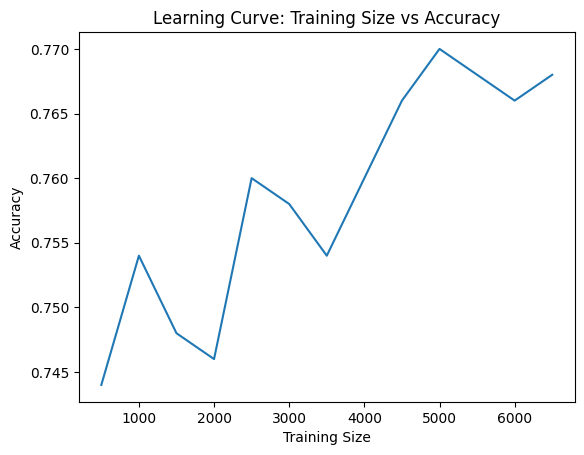

In [ ]:
import matplotlib.pyplot as plt

# Plot learning curve
plt.figure()
plt.plot(training_sizes, accuracies)
plt.xlabel("Training Size")
plt.ylabel("Accuracy")
plt.title("Learning Curve: Training Size vs Accuracy")
plt.show()

# 5_Change the feature has(x) to count(x)

Now let's change one of the features a little bit. Instead of asking whether the name contains each of the 26 letters, let's revise the feature to count how many occurrences of each letter are there in a name.

# YOUR TURN 3

In the next function, gender_features3, let's change the feature has(x) to count(x). Please complete the rest of the feature.

In [ ]:
def gender_features3(name):
    features = {}
    features["first_letter"] = name[0].lower()
    features["last_letter"] = name[-1].lower()
    for letter in 'abcdefghijklmnopqrstuvwxyz':
        features["count({})".format(letter)] = name.lower().count(letter)
    return features

In [ ]:
featuresets = [(gender_features3(n), gender) for (n, gender) in labeled_names]
train_set, test_set = featuresets[500:], featuresets[:500]
classifier = nltk.NaiveBayesClassifier.train(train_set)
print(nltk.classify.accuracy(classifier, test_set))

0.78


# 6_Adding a dev-test set

Once an initial set of features has been chosen, a very productive method for refining the feature set is error analysis. First, we select a development set, containing the corpus data for creating the model. This development set is then subdivided into the training set and the dev-test set.

In [ ]:
train_names = labeled_names[1500:]
devtest_names = labeled_names[500:1500]
test_names = labeled_names[:500]

Having divided the corpus into appropriate datasets, we train a model using the new training set, and then run it on the dev-test set.

In [ ]:
train_set = [(gender_features3(n), gender) for (n, gender) in train_names]
devtest_set = [(gender_features3(n), gender) for (n, gender) in devtest_names]
test_set = [(gender_features3(n), gender) for (n, gender) in test_names]
classifier = nltk.NaiveBayesClassifier.train(train_set)
print(nltk.classify.accuracy(classifier, devtest_set))

0.791


Using the dev-test set, we can generate a list of the errors that the classifier makes when predicting name genders:

In [ ]:
errors = []
for (name, tag) in devtest_names:
    guess = classifier.classify(gender_features(name))
    if guess != tag:
        errors.append( (tag, guess, name) )

We can then examine individual error cases where the model predicted the wrong label, and try to determine what additional pieces of information would allow it to make the right decision (or which existing pieces of information are tricking it into making the wrong decision). The feature set can then be adjusted accordingly. The names classifier that we have built generates about 100 errors on the dev-test corpus:

In [ ]:
for (tag, guess, name) in sorted(errors):
  print('correct={} guess={} name={}'.format(tag, guess, name))

correct=female guess=male name=Abigail
correct=female guess=male name=Allison
correct=female guess=male name=Allys
correct=female guess=male name=Allyson
correct=female guess=male name=Ambur
correct=female guess=male name=Annabal
correct=female guess=male name=Annabell
correct=female guess=male name=Aryn
correct=female guess=male name=Astrix
correct=female guess=male name=Aurel
correct=female guess=male name=Bel
correct=female guess=male name=Beryl
correct=female guess=male name=Bidget
correct=female guess=male name=Brett
correct=female guess=male name=Brigit
correct=female guess=male name=Bryn
correct=female guess=male name=Cal
correct=female guess=male name=Cam
correct=female guess=male name=Caril
correct=female guess=male name=Carmel
correct=female guess=male name=Catlin
correct=female guess=male name=Charin
correct=female guess=male name=Charmian
correct=female guess=male name=Cherilynn
correct=female guess=male name=Cherin
correct=female guess=male name=Christin
correct=female gue

Looking through this list of errors makes it clear that some suffixes that are more than one letter can be indicative of name genders. For example, names ending in yn appear to be predominantly female, despite the fact that names ending in n tend to be male; and names ending in ch are usually male, even though names that end in h tend to be female. We therefore adjust our feature extractor to include features for two-letter suffixes:

# YOUR TURN 4

Let's add a feature "suffix" to capture the last two letters of the name. Complete the following function.

In [ ]:
def gender_features4(name):
    features = {}
    features["first_letter"] = name[0].lower()
    features["last_letter"] = name[-1].lower()
    features["suffix"]= name[-2:].lower()
    for letter in 'abcdefghijklmnopqrstuvwxyz':
        features["count({})".format(letter)] = name.lower().count(letter)
    return features

In [ ]:
train_set = [(gender_features4(n), gender) for (n, gender) in train_names]
devtest_set = [(gender_features4(n), gender) for (n, gender) in devtest_names]
test_set = [(gender_features4(n), gender) for (n, gender) in test_names]
classifier = nltk.NaiveBayesClassifier.train(train_set)

In [ ]:
print(nltk.classify.accuracy(classifier, devtest_set))

0.808


In [ ]:
print(nltk.classify.accuracy(classifier, test_set))

0.788


# YOUR TURN 5
Modify the gender_features4() function to provide the classifier with one more feature of the length of the name, retrain the classifier, and test its accuracy.

In [ ]:
def gender_features5(name):
  features = {}
  features["first_letter"] = name[0].lower()
  features["last_letter"] = name[-1].lower()
  features["suffix"]= name[-2:].lower()
  features["length"] = len(name)

  for letter in 'abcdefghijklmnopqrstuvwxyz':
    features["count({})".format(letter)] = name.lower().count(letter)
  return features

In [ ]:
# split the data
train_set = [(gender_features5(n), gender) for (n, gender) in train_names]
devtest_set = [(gender_features5(n), gender) for (n, gender) in devtest_names]
test_set = [(gender_features5(n), gender) for (n, gender) in test_names]

In [ ]:
# build and train the classifier
classifier = nltk.NaiveBayesClassifier.train(train_set)

In [ ]:
# print the accuracy of predictions on the dev-test set
print(nltk.classify.accuracy(classifier, devtest_set))

0.806


In [ ]:
# print the accuracy of predictions on the test set
print(nltk.classify.accuracy(classifier, test_set))

0.788
